# TUM 2022 Volkswagen ID.3 powertrain data

This notebook lists the one vehicle and its drives, loads one drive, and plots pack voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('tum_id3_2022')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('tum_id3_2022')
display(released)

,unit,vehicle,same_as,tracks,first,last
0,ID3,VW ID.3 Pro Performance,tumftm ID1,148,2021-02-11 08:00:50,2021-12-08 14:14:20.900


The one vehicle is tumftm's ID1, counted once there. This release adds pack current and the 108 cell voltages for the same car.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('tum_id3_2022', track=0)
print(frame.shape)
display(frame.head())

(5550, 137)


,track,acc_x,acc_y,acc_z,altitude_baro,altitude_gps,axle_torque,axle_torque_nominal,battery_voltage,cal_distance_covered,...,num_sats,pack_temp_0,pressure,ptc_batt_current,speed,temp_ac_outlet_fl,temperature,time,vehicle_speed,cal_speed_combined
0,0,2.02032,-9.56480,-0.43432,395.91,489.66,0,0.0,15.23,NaN,...,NaN,-1.5,96659.2,NaN,0.04,0,-7.83,1613030450000,0,0.14
1,0,2.02032,-9.56480,-0.43432,395.91,489.66,0,0.0,15.23,NaN,...,NaN,-1.5,96659.2,NaN,0.04,0,-7.83,1613030450100,0,0.14
2,0,2.02032,-9.56480,-0.43432,395.91,489.66,0,0.0,15.23,NaN,...,NaN,-1.5,96659.2,NaN,0.04,0,-7.83,1613030450200,0,0.14
3,0,2.04960,-9.56968,-0.45384,395.91,489.66,0,0.0,15.23,NaN,...,NaN,-1.5,96659.2,NaN,0.04,0,-7.83,1613030450300,0,0.14
4,0,2.02520,-9.56480,-0.42944,395.91,489.66,0,0.0,15.23,NaN,...,NaN,-1.5,96659.2,NaN,0.04,0,-7.83,1613030450400,0,0.14


Drive 0 at one row per 0.1 s. Drives differ in their columns.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['hv_battery_current', 'hv_battery_voltage', 'hv_soc']].describe().T)

,count,mean,std,min,25%,50%,75%,max
hv_battery_current,5550.0,-20.827865,21.379690,-126.27,-29.51,-13.81,-9.7,16.55
hv_battery_voltage,5550.0,441.809369,4.117618,425.50,439.50,442.00,445.0,448.50
hv_soc,5550.0,94.145225,0.813890,92.80,93.60,94.00,94.8,95.60


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

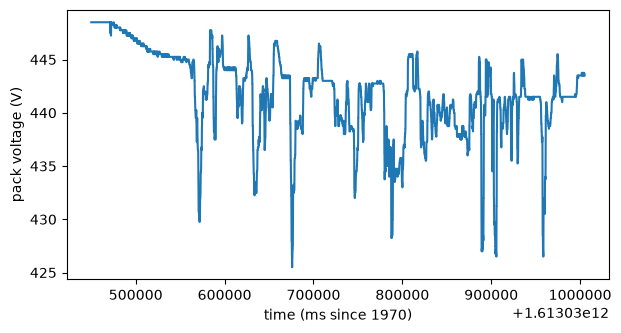

In [4]:
ax = frame.plot(x='time', y='hv_battery_voltage', figsize=(7, 3.5), legend=False)
ax.set_xlabel('time (ms since 1970)')
ax.set_ylabel('pack voltage (V)')
plt.show()

During this drive pack voltage ranges from 425.5 to 448.5 V while SOC goes from 95.6 to 92.8 percent. Values are raw, as released.